# off出力層：評価に使うニューロン数と素材分類精度

`p_E_readout-0.11__g_e_out-0.2706/off/rep1/test`に保存された出力層の発火記録を使います。
ネットワーク・重み・gainは固定し、**分類器へ与えるニューロンだけを減らします**。
各ニューロンの25 ms×20ビン（500 ms全部）を使い、PCA・標準化は行いません。

- ニューロン数：80、75、70、…、10、5、1個（下の設定で変更可能）
- 選び方：独立したランダム削減順を10通り作り、それぞれで同じ順にニューロンを減らします。
  ある削減順では、少ないニューロンの集合は、多いニューロンの集合に含まれます。
- 分類方法：既存Excelと同じクラス別正則化マハラノビス距離（正則化係数1e-6）
- 評価：全条件で同じ層別10分割。各素材100試行から90試行を分類器学習、10試行を評価に使用します。
- 80個は毎回同じ集合なので1回だけ計算し、10回の行に再利用します。
- 図の帯は**ニューロンの選び方10通りの標準偏差**です。交差検証の分割間の標準偏差ではありません。

図・表はこのノートブック内だけに表示します。元データ・実験結果は変更しません。


In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits

# h_analysis、LSM、研究コードのいずれから実行してもプロジェクトを探す。
cwd = Path.cwd().resolve()
PROJECT = next((candidate for parent in (cwd, *cwd.parents)
                for candidate in (parent, parent / "LSM")
                if (candidate / "d_tools/classification.py").is_file()), None)
if PROJECT is None:
    raise FileNotFoundError("LSMプロジェクトが見つかりません。")
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from d_tools.classification import classify
from d_tools.recording_io import read_record
from d_tools.evaluation_excel import load_classification_results

SOURCE = (PROJECT / "g_tactile_results/readout_run"
          / "p_E_readout-0.11__g_e_out-0.2706/off/rep1/test")
N_SELECTIONS = 10
SELECTION_SEED = 12345
REGULARIZATION = 1e-6
THREADS = 4

# 完成済みファイルだけを読み、計算途中のpartial.npyは使用しない。
record_path = SOURCE / "rec/readout/sout_rec_rep1.npy"
if not record_path.is_file():
    raise FileNotFoundError(f"off rep1のテスト完了後に実行してください: {record_path}")
metadata = read_record(SOURCE / "test_config_snapshot.json")
counts = np.load(record_path, allow_pickle=False)
if counts.ndim != 4 or not np.isfinite(counts).all() or np.any(counts < 0):
    raise ValueError("素材×試行×ニューロン×時間ビンの非負発火数が必要です。")
MATERIALS = list(metadata["materials"])
# 1 ms記録をメモリ上で25 msへ集約し、別のnpyファイルは作らない。
BIN_MS = 25.0
recording_bin_ms = float(metadata["recording_bin_width_ms"])
step = round(BIN_MS / recording_bin_ms)
if step < 1 or not np.isclose(step * recording_bin_ms, BIN_MS) or counts.shape[-1] % step:
    raise ValueError("記録のビン幅から25 msへ集約できません。")
counts = counts.reshape(*counts.shape[:-1], counts.shape[-1] // step, step).sum(axis=-1)
N_CLASSES, N_TRIALS, N_NEURONS, N_TIME_BINS = counts.shape
assert N_CLASSES == len(MATERIALS) == 8 and N_NEURONS == 80
assert BIN_MS == 25 and N_TIME_BINS == 20
REP = int(metadata.get("rep", 1))
N_FOLDS = int(metadata["eval"]["EVAL_N_FOLDS"])
CV_SEED = int(metadata["eval"]["EVAL_BASE_SEED"]) + REP - 1
if N_TRIALS < N_FOLDS:
    raise ValueError("交差検証の分割数より試行数が少なくなっています。")

# ここをlist(range(N_NEURONS, 0, -1))にすると1個刻みで評価できる。
NEURON_COUNTS = sorted(set([*range(N_NEURONS, 0, -5), 1]), reverse=True)
states_hz = (counts.astype(np.float64) / (BIN_MS / 1000)).reshape(
    N_CLASSES * N_TRIALS, N_NEURONS, N_TIME_BINS)
labels = np.repeat(np.arange(N_CLASSES), N_TRIALS)
splits = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=CV_SEED)
              .split(np.zeros(len(labels)), labels))
np.testing.assert_array_equal(np.sort(np.concatenate([test for _, test in splits])),
                              np.arange(len(labels)))
print("Source:", SOURCE)
print("States:", states_hz.shape, "| bin:", BIN_MS, "ms | CV seed:", CV_SEED)
print("Neuron counts:", NEURON_COUNTS, "| random removal orders:", N_SELECTIONS)
print("Each classification uses all time bins; no PCA or standardization.")


Source: C:\Users\haru4\研究\研究コード\LSM\g_tactile_results\readout_run\p_E_readout-0.11__g_e_out-0.2706\off\rep1\test
States: (800, 80, 20) | bin: 25.0 ms | CV seed: 1
Neuron counts: [80, 75, 70, 65, 60, 55, 50, 45, 40, 35, 30, 25, 20, 15, 10, 5, 1] | random removal orders: 10
Each classification uses all time bins; no PCA or standardization.


In [2]:
def evaluate_selected_neurons(neuron_ids):
    """指定ニューロンだけで全CV分割を評価し、正解数と分割別正答率を返す。"""
    neuron_ids = np.sort(np.asarray(neuron_ids, dtype=int))
    if len(neuron_ids) == 0 or len(np.unique(neuron_ids)) != len(neuron_ids):
        raise ValueError("ニューロンIDは重複のない1個以上の集合にしてください。")
    features = states_hz[:, neuron_ids, :].reshape(len(labels), -1)
    correct = 0
    fold_accuracies = []
    for train, test in splits:
        # 既存評価と同じく、分類器学習側に発火がある特徴だけを使う。
        active = np.any(features[train] != 0, axis=0)
        if not active.any():
            # 未発火の集合に意味のない予測を割り当てず、評価不能として記録する。
            return np.nan, []
        predicted = classify(features[train][:, active], labels[train], features[test][:, active],
                             regularization=REGULARIZATION)
        correct += int(np.count_nonzero(predicted == labels[test]))
        fold_accuracies.append(100 * float(np.mean(predicted == labels[test])))
    return 100 * correct / len(labels), fold_accuracies


# 全80個の基準値を先に計算し、既存Excelの正答率とも照合する。
started = time.perf_counter()
with threadpool_limits(limits=THREADS):
    baseline_accuracy, baseline_folds = evaluate_selected_neurons(np.arange(N_NEURONS))
print(f"All {N_NEURONS} neurons: {baseline_accuracy:.4f}% "
      f"({time.perf_counter()-started:.1f} seconds)", flush=True)
saved_evaluation = load_classification_results(SOURCE / "eval/classification.xlsx")
if saved_evaluation is not None:
    saved_rows = [row for row in saved_evaluation["summary"]
                  if int(row["rep"]) == REP and float(row["T_n_ms"]) == BIN_MS]
    if saved_rows and saved_evaluation["base_seed"] + REP - 1 == CV_SEED:
        expected_accuracy = 100 * float(saved_rows[0]["accuracy"])
        np.testing.assert_allclose(baseline_accuracy, expected_accuracy, atol=1e-8)
        print(f"Matches existing Excel: {expected_accuracy:.4f}%", flush=True)


All 80 neurons: 79.3750% (1.6 seconds)
Matches existing Excel: 79.3750%


In [3]:
# 10通りの独立した削減順。乱数は分類器・ネットワークの乱数とは分ける。
rng = np.random.default_rng(SELECTION_SEED)
removal_orders = [rng.permutation(N_NEURONS) for _ in range(N_SELECTIONS)]
selection_rows = []
fold_rows = []
started = time.perf_counter()
with threadpool_limits(limits=THREADS):
    for selection, order in enumerate(removal_orders, 1):
        for n_neurons in NEURON_COUNTS:
            selected = np.sort(order[:n_neurons])
            if n_neurons == N_NEURONS:
                accuracy, fold_values = baseline_accuracy, baseline_folds
            else:
                accuracy, fold_values = evaluate_selected_neurons(selected)
            selection_rows.append({"n_neurons": n_neurons, "selection": selection,
                                   "accuracy_percent": accuracy,
                                   "neuron_ids": selected.tolist()})
            fold_rows.extend({"n_neurons": n_neurons, "selection": selection,
                              "fold": fold, "accuracy_percent": value}
                             for fold, value in enumerate(fold_values, 1))
        print(f"Random removal order {selection}/{N_SELECTIONS} complete | "
              f"elapsed {time.perf_counter()-started:.1f} s", flush=True)
selection_results = pd.DataFrame(selection_rows)
fold_results = pd.DataFrame(fold_rows)
summary = (selection_results.groupby("n_neurons")["accuracy_percent"]
           .agg(mean="mean", std="std", minimum="min", maximum="max", valid_selections="count")
           .sort_index(ascending=False).reset_index())
summary["total_selections"] = N_SELECTIONS
print(f"Completed in {time.perf_counter()-started:.1f} seconds.")
display(summary.round(4))


Random removal order 1/10 complete | elapsed 13.7 s
Random removal order 2/10 complete | elapsed 27.3 s
Random removal order 3/10 complete | elapsed 41.1 s
Random removal order 4/10 complete | elapsed 54.6 s
Random removal order 5/10 complete | elapsed 68.1 s
Random removal order 6/10 complete | elapsed 81.9 s
Random removal order 7/10 complete | elapsed 95.6 s
Random removal order 8/10 complete | elapsed 109.3 s
Random removal order 9/10 complete | elapsed 123.0 s
Random removal order 10/10 complete | elapsed 136.7 s
Completed in 136.8 seconds.


n_neurons,mean,std,minimum,maximum,valid_selections,total_selections
80,79.3750,0.0000,79.375,79.375,10,10
75,79.6000,0.7449,77.750,80.250,10,10
70,78.8000,1.1368,77.000,80.625,10,10
65,78.2375,1.1703,76.500,80.125,10,10
60,77.5750,1.5726,75.500,80.875,10,10
55,76.7000,1.6512,74.625,80.125,10,10
50,75.9750,1.2525,74.000,77.875,10,10
45,75.0250,1.3741,72.875,77.750,10,10
40,74.1125,1.6142,71.625,76.750,10,10
35,72.7625,2.3684,68.750,76.000,10,10


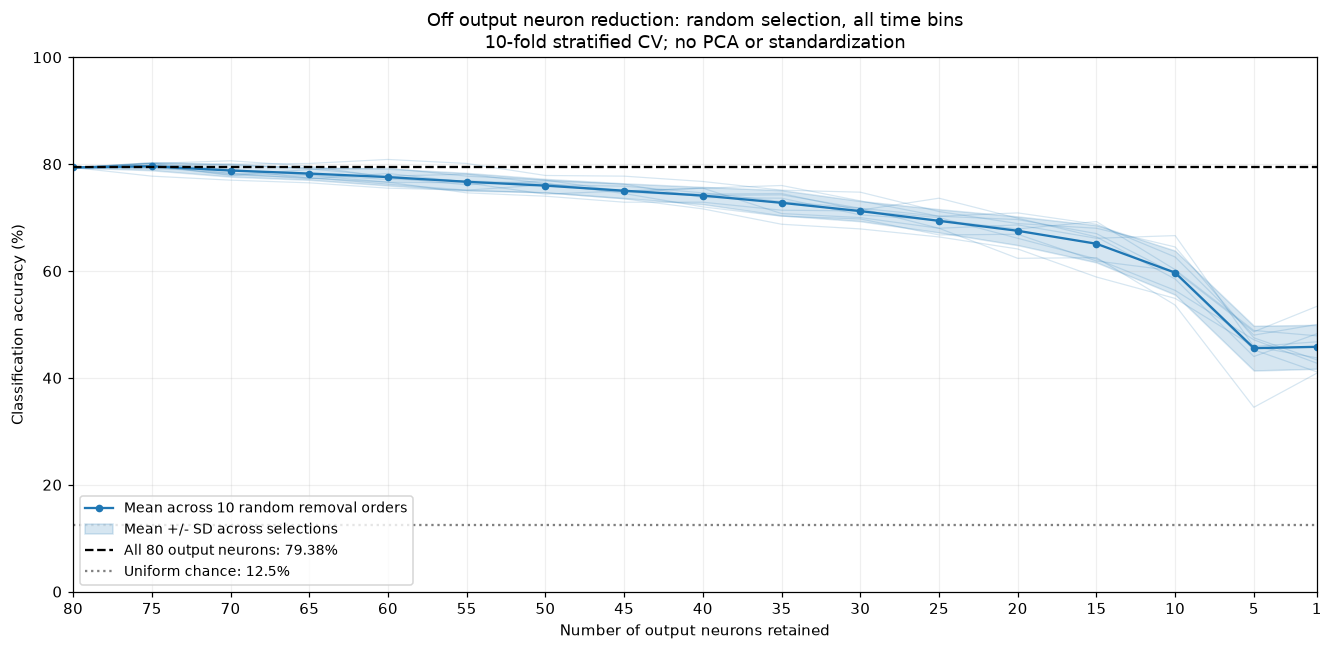

n_neurons,mean,std,minimum,maximum,valid_selections,total_selections
80,79.3750,0.0000,79.375,79.375,10,10
40,74.1125,1.6142,71.625,76.750,10,10
20,67.5250,2.6828,62.375,70.875,10,10
10,59.6875,4.1186,53.625,66.625,10,10
5,45.5625,4.1846,34.500,48.875,10,10
1,45.8125,4.1059,40.875,53.375,10,10


In [4]:
# 横軸は80個から1個へ。細線が10通り、太線が平均、帯が標準偏差。
fig, ax = plt.subplots(figsize=(12, 5.8), layout="constrained")
for _, rows in selection_results.groupby("selection"):
    rows = rows.sort_values("n_neurons", ascending=False)
    ax.plot(rows.n_neurons, rows.accuracy_percent, color="tab:blue", alpha=0.18, linewidth=0.8)
x = summary.n_neurons.to_numpy()
mean = summary["mean"].to_numpy()
sd = summary["std"].fillna(0).to_numpy()
ax.plot(x, mean, "o-", color="tab:blue", markersize=4, label="Mean across 10 random removal orders")
ax.fill_between(x, np.clip(mean-sd, 0, 100), np.clip(mean+sd, 0, 100),
                color="tab:blue", alpha=0.18, label="Mean +/- SD across selections")
ax.axhline(baseline_accuracy, color="black", linestyle="--",
           label=f"All {N_NEURONS} output neurons: {baseline_accuracy:.2f}%")
ax.axhline(100/N_CLASSES, color="gray", linestyle=":", label=f"Uniform chance: {100/N_CLASSES:.1f}%")
ax.set(xlim=(N_NEURONS, 1), ylim=(0, 100),
       xlabel="Number of output neurons retained", ylabel="Classification accuracy (%)",
       title=("Off output neuron reduction: random selection, all time bins\n"
              f"{N_FOLDS}-fold stratified CV; no PCA or standardization"))
ax.set_xticks(sorted(set([1, *range(5, N_NEURONS+1, 5)])))
ax.grid(alpha=0.2)
ax.legend(loc="lower left", fontsize=9)
plt.show()

# 少数ニューロンの条件を抜き出して比較する。
display(summary[summary.n_neurons.isin([80, 40, 20, 10, 5, 1])].round(4))


## 解釈上の注意

- これはネットワークの出力ニューロンを物理的に減らした再シミュレーションではありません。
  保存された80個の出力から、分類に使用するニューロンだけを選んでいます。
- 小さい集合でも精度が維持されれば、その集合の発火応答から素材情報を読み取れることを示します。
  各ニューロンが同じ情報を持つ、あるいは未選択のニューロンが不要、とまでは断定できません。
- ニューロン数に対して精度が単調になるとは限りません。分類器の推定と入力集合の両方が変わります。
- 10回で変えているのは**ニューロン選択**です。ネットワークseed・入力試行・交差検証分割は固定です。
- 未発火ニューロンだけの集合などで評価不能な場合はNaNとし、valid_selectionsを確認してください。
- 他のrepも比較する場合はSOURCEを変更して再実行してください。
